# 07 — YOLOv8-seg ile Lezyon Segmentasyonu

Çalışmanın **nihai ve dağıtılan** segmentasyon modeli. Masaüstü arayüzünde
(`app/lungscan_gui.py`) ve sürüm notlarında paylaşılan `best.pt` ağırlıkları bu
notebook'ta üretilir.

## Neden YOLOv8-seg?

| Yaklaşım | Notebook | Sonuç |
|---|---|---|
| U-Net | `05` | Piksel düzeyinde iyi, ancak model kesitte lezyon olup olmadığını bilmez ve tek bir "lezyon" varsayar |
| Mask R-CNN (Detectron2) | `06` | Doğru sonuç, ancak iki aşamalı olduğu için yavaş |
| **YOLOv8-seg** | `07` | Tek aşamalı: sınıf + kutu + maske birlikte; hem hızlı hem yeterince doğru |

YOLOv8-seg, çok sayıda lezyonu aynı kesitte ayrı ayrı bulabilir ve her biri için
güven skoru verir. Bu, klinik kullanımda (radyolog onayı) gerekli olan
belirsizliğin raporlanmasını mümkün kılar.

## Model karşılaştırması

Farklı model boyutlarının karşılaştırması
`notebooks/denemeler/yolov8_model_karsilastirmasi/` altındadır. Bu notebook'ta
seçilen yapılandırma şudur:

| Ayar | Değer |
|---|---|
| Model | `yolov8m-seg.pt` (COCO üzerinde ön eğitilmiş) |
| Epoch | 100 |
| Görüntü boyutu | 640 |
| Sınıf sayısı | 1 (`Cancer`) |
| Veri kümesi | 789 eğitim / 198 doğrulama kesiti |

## Kaydedilen sonuçlar

| Ölçüt | Kutu (box) | Maske (mask) |
|---|---|---|
| Kesinlik (P) | 0,894 | 0,861 |
| Duyarlılık (R) | 0,807 | 0,773 |
| mAP@50 | 0,893 | 0,838 |
| mAP@50-95 | 0,576 | 0,472 |


## 1. Ortam ve veri kümesi


In [ ]:
# Colab kullanıyorsanız:
# from google.colab import drive
# drive.mount("/content/drive")
# %pip install -q ultralytics

import os
import shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------------------------------------------------------------- yollar
DATA_ROOT = "/content/drive/MyDrive/lungscan"
DATASET_DIR = os.path.join(DATA_ROOT, "dataset")
IMAGES_TRAIN = os.path.join(DATASET_DIR, "images/train")
IMAGES_VAL = os.path.join(DATASET_DIR, "images/val")
LABELS_TRAIN = os.path.join(DATASET_DIR, "labels/train")
LABELS_VAL = os.path.join(DATASET_DIR, "labels/val")
RUNS_DIR = os.path.join(DATA_ROOT, "runs")
DATA_CONFIG = os.path.join(DATA_ROOT, "veri_kumesi.yaml")

# ------------------------------------------------------------- parametreler
IMAGE_SIZE = 640
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.5
CLASS_NAMES = ["Cancer"]

os.makedirs(RUNS_DIR, exist_ok=True)


In [ ]:
def write_data_config(path, dataset_dir, class_names):
    """Ultralytics'in beklediği veri kümesi tanım dosyasını yazar.

    Dosya biçimi (bkz. depodaki `configs/lungscan_yolo_dataset.yaml`):
        path:  veri kümesi kökü
        train: eğitim görüntülerinin alt klasörü
        val:   doğrulama görüntülerinin alt klasörü
        nc:    sınıf sayısı
        names: sınıf adları
    """
    content = (
        "# LungScan - YOLOv8 segmentasyon veri kumesi tanimi\n"
        f"path: {dataset_dir}\n"
        "train: images/train\n"
        "val: images/val\n"
        "\n"
        f"nc: {len(class_names)}\n"
        f"names: {class_names}\n"
    )
    with open(path, "w", encoding="utf-8") as f:
        f.write(content)
    print(content)
    return path


write_data_config(DATA_CONFIG, DATASET_DIR, CLASS_NAMES)

print("Eğitim görüntüsü :", len(os.listdir(IMAGES_TRAIN)))
print("Doğrulama görüntüsü:", len(os.listdir(IMAGES_VAL)))


### 1.1 Yardımcı fonksiyonlar

Tahmin maskelerini üretmek, etiketleri maskeye çevirmek ve maskeleri
karşılaştırmak için kullanılan fonksiyonlar.


In [ ]:
def yolo_label_to_masks(label_path, size):
    """YOLO poligon etiketini, her poligon için bir ikili maske listesine çevirir.

    Bir kesitte birden fazla lezyon olabilir; etiket dosyasındaki her satır ayrı
    bir lezyondur ve ayrı bir maske üretir.

    Args:
        label_path: `<class> <x1> <y1> ...` satırlarını içeren .txt dosyası.
        size:       (genişlik, yükseklik).

    Returns:
        np.uint8 maskeler listesi (anotasyonsuz kesitte boş liste).
    """
    width, height = size
    masks = []

    if not os.path.exists(label_path):
        return masks

    with open(label_path, encoding="utf-8") as f:
        for line in f:
            parts = line.split()
            if len(parts) < 7:                      # sınıf + en az 3 nokta
                continue

            coords = np.array([float(v) for v in parts[1:]], dtype=float)
            points = np.stack([coords[0::2] * width, coords[1::2] * height], axis=1)

            mask = np.zeros((height, width), dtype=np.uint8)
            cv2.fillPoly(mask, [points.astype(np.int32)], 1)
            masks.append(mask)

    return masks


def combine_masks(masks, shape):
    """Birden fazla maskeyi tek bir ikili maskede birleştirir (gösterim için)."""
    combined = np.zeros(shape, dtype=np.uint8)
    for mask in masks:
        combined = np.maximum(combined, mask)
    return combined


def predicted_masks(model, image, conf=CONF_THRESHOLD):
    """Bir görüntü için modelin ürettiği maskeleri orijinal boyuta getirir."""
    height, width = image.shape[:2]
    result = model.predict(image, conf=conf, verbose=False)[0]

    masks = []
    if result.masks is not None:
        for mask in result.masks.data.cpu().numpy():
            masks.append(cv2.resize(mask, (width, height)))
    return masks


## 2. Eğitim

Ultralytics'in `train` arayüzü kullanılır. Kayıp fonksiyonu, veri artırma ve
öğrenme oranı planı kütüphane tarafından yönetilir; model tipi dışında bir
değişiklik yapılmamıştır.

> **Terk edilen yaklaşım:** İlk sürümde YOLOv8, elle yazılmış bir PyTorch eğitim
> döngüsüne sokulmaya çalışılmıştı (`for epoch in range(...): with torch.no_grad():
> outputs = model(images)` ardından `criterion(outputs, labels)`). Bu yaklaşım
> temelden hatalıdır:
>
> * Ultralytics modelleri `__call__` çağrısında **NMS uygulanmış tahmin listesi**
>   döndürür, eğitim için gereken ham öznitelik haritalarını değil.
> * YOLOv8'in kaybı (sınıflandırma + kutu + DFL + maske terimleri) modelin kendi
>   `loss` metodunda hesaplanır ve `task="segment"` için özel hedef ataması
>   (task-aligned assigner) gerektirir. Dışarıdan `cross_entropy` uygulamak
>   anlamsızdır.
> * Segmentasyon çıktısı ile etiket şekli uyuşmadığı için döngü hiçbir zaman
>   öğrenmeye başlamaz.
>
> Doğru yol, kütüphanenin kendi `train` arayüzünü kullanmaktır — bu notebook
> öyle yapar.


In [ ]:
model = YOLO("yolov8m-seg.pt")

results = model.train(
    data=DATA_CONFIG,
    epochs=100,
    imgsz=IMAGE_SIZE,
    batch=16,
    project=RUNS_DIR,
    name="yolov8m_seg",
    seed=0,
    patience=20,          # 20 epoch iyileşme olmazsa dur
    exist_ok=True,
)
print("Ağırlıklar:", os.path.join(str(results.save_dir), "weights/best.pt"))


## 3. Doğrulama

`model.val()`, doğrulama kümesinde hem kutuyu hem maskeyi COCO metrikleriyle
değerlendirir. Dönen `best.pt` ağırlıkları, sürüm notlarında paylaşılan modelin
kaynağıdır.


In [ ]:
metrics = model.val(data=DATA_CONFIG, split="val")

print(f"Kutu  — P: {metrics.box.p.mean():.3f} | R: {metrics.box.r.mean():.3f} | "
      f"mAP50: {metrics.box.map50:.3f} | mAP50-95: {metrics.box.map:.3f}")
print(f"Maske — P: {metrics.seg.p.mean():.3f} | R: {metrics.seg.r.mean():.3f} | "
      f"mAP50: {metrics.seg.map50:.3f} | mAP50-95: {metrics.seg.map:.3f}")


## 4. Tahmin ve görselleştirme

### 4.1 Tahmin edilen konturlar

Lezyon sınırı yalnızca **kontur** olarak çizilir; görüntünün tanısal içeriği
kapatılmaz.


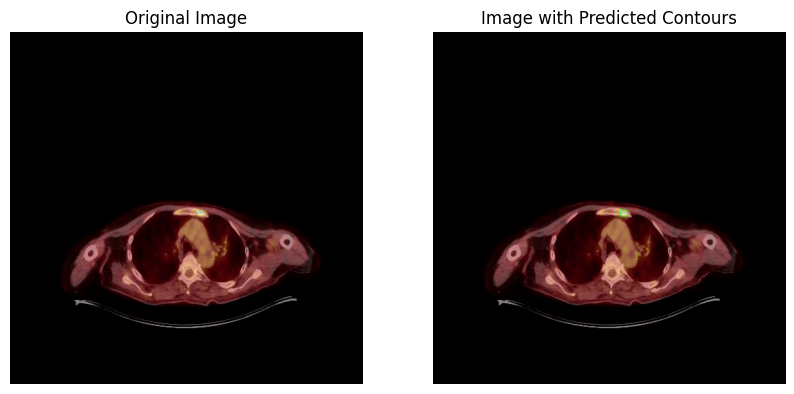

In [ ]:
def draw_predicted_contours(model, image_path, conf=CONF_THRESHOLD, colour=(0, 255, 0)):
    """Bir kesitin tahmin konturlarını çizer; (orijinal, konturlu) döndürür."""
    image = cv2.imread(image_path)
    canvas = image.copy()

    for mask in predicted_masks(model, image, conf=conf):
        binary = (mask > 0.5).astype(np.uint8) * 255
        contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(canvas, contours, -1, colour, 2)

    return image, canvas


sample_name = sorted(f for f in os.listdir(IMAGES_VAL) if f.endswith(".png"))[0]
sample_path = os.path.join(IMAGES_VAL, sample_name)

original, with_contours = draw_predicted_contours(model, sample_path)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title(f"Orijinal — {sample_name}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(with_contours, cv2.COLOR_BGR2RGB))
plt.title("Tahmin edilen konturlar")
plt.axis("off")

plt.tight_layout()
plt.show()


### 4.2 Tahmin ile gerçek maskenin karşılaştırılması


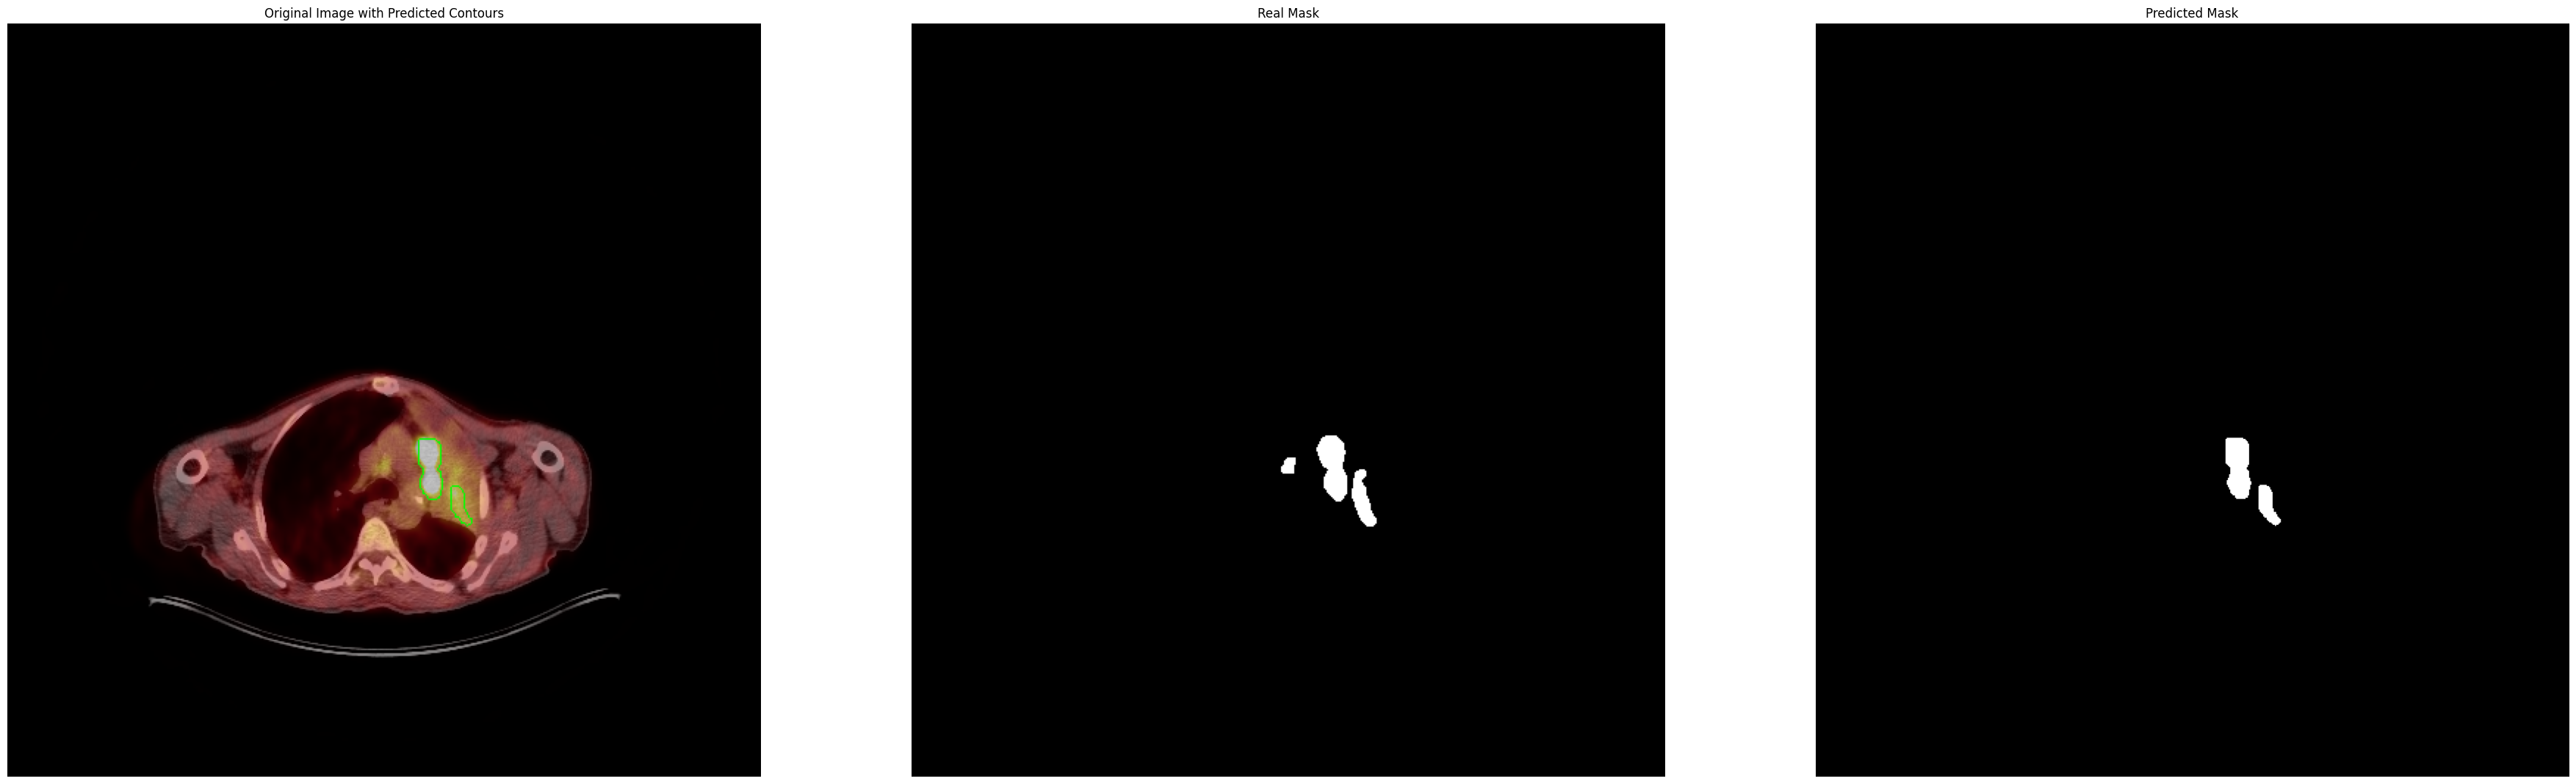

In [ ]:
real_masks = yolo_label_to_masks(
    os.path.join(LABELS_VAL, os.path.splitext(sample_name)[0] + ".txt"),
    (original.shape[1], original.shape[0]),
)
real_mask = combine_masks(real_masks, original.shape[:2])

preds = predicted_masks(model, original)
predicted_mask = combine_masks([(m > 0.5).astype(np.uint8) for m in preds],
                               original.shape[:2])

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
plt.title("Girdi kesiti")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(real_mask, cmap="gray")
plt.title("Gerçek maske (etiketten)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_mask, cmap="gray")
plt.title(f"Tahmin ({len(preds)} maske)")
plt.axis("off")

plt.tight_layout()
plt.show()


## 5. IoU ve eşleştirme

Modelin başarısını ölçmek için tahmin maskeleri, etiketlerden üretilen gerçek
maskelerle IoU'ya göre eşleştirilir.

* IoU ≥ 0,5 → **doğru pozitif (TP)**
* eşleşmeyen tahmin → **yanlış pozitif (FP)**
* eşleşmeyen gerçek maske → **yanlış negatif (FN)**


In [ ]:
def mask_iou(mask_a, mask_b):
    """İki ikili maske arasındaki IoU (Jaccard) skoru."""
    a = mask_a > 0.5
    b = mask_b > 0
    union = np.logical_or(a, b).sum()
    if union == 0:
        return 0.0
    return float(np.logical_and(a, b).sum() / union)


def match_masks(pred_masks, real_masks, iou_threshold=IOU_THRESHOLD):
    """Tahmin ve gerçek maskeleri IoU'ya göre eşleştirir (açgözlü algoritma).

    Her gerçek maske için en yüksek IoU'lu, henüz eşleşmemiş tahmin aranır.

    Returns:
        (eşleşmeler, eşleşmeyen tahmin sayısı, eşleşmeyen gerçek sayısı)
        Burada `eşleşmeler` = [(tahmin_indeksi, gerçek_indeksi, iou), ...]
    """
    iou_matrix = np.zeros((len(pred_masks), len(real_masks)))
    for p, pred in enumerate(pred_masks):
        for r, real in enumerate(real_masks):
            iou_matrix[p, r] = mask_iou(pred, real)

    matches, matched_pred, matched_real = [], set(), set()
    for r in range(len(real_masks)):
        for p in np.argsort(-iou_matrix[:, r]):
            if p in matched_pred:
                continue
            if iou_matrix[p, r] >= iou_threshold:
                matched_pred.add(int(p))
                matched_real.add(r)
                matches.append((int(p), r, float(iou_matrix[p, r])))
            break

    return matches, len(pred_masks) - len(matched_pred), len(real_masks) - len(matched_real)


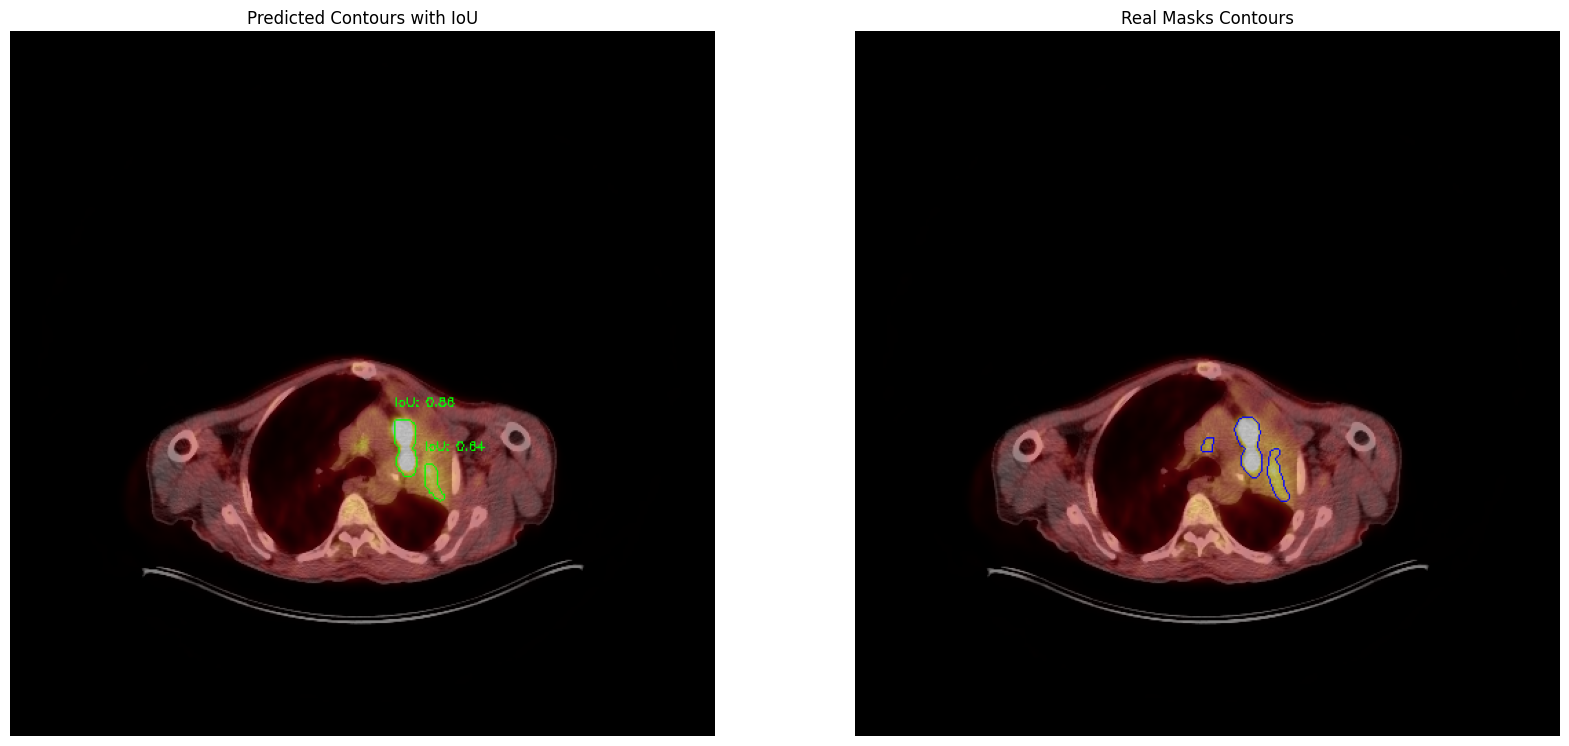

In [ ]:
matches, missed_pred, missed_real = match_masks(preds, real_masks)

img_with_predicted = original.copy()
img_with_real = original.copy()

for mask in preds:
    binary = (mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(img_with_predicted, contours, -1, (0, 255, 0), 2)

if real_mask.sum() > 0:
    contours, _ = cv2.findContours(real_mask.astype(np.uint8) * 255,
                                   cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(img_with_real, contours, -1, (255, 0, 0), 2)

best_iou = max((iou for _, _, iou in matches), default=0.0)

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_with_predicted, cv2.COLOR_BGR2RGB))
plt.title(f"Tahmin edilen konturlar (en iyi IoU = {best_iou:.3f})")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_with_real, cv2.COLOR_BGR2RGB))
plt.title("Gerçek konturlar")
plt.axis("off")

plt.tight_layout()
plt.show()

print(f"TP={len(matches)}  FP={missed_pred}  FN={missed_real}")


## 6. TP / FP / FN ve karışıklık matrisi


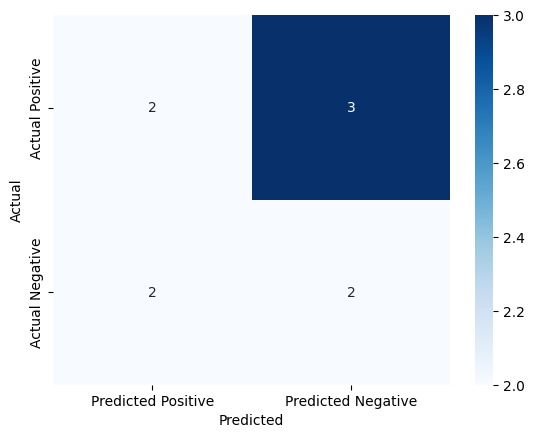

In [ ]:
conf_matrix = np.array([[len(matches), missed_real], [missed_pred, 0]])

plt.figure(figsize=(5, 4))
plt.imshow(conf_matrix, cmap="Blues")
for (i, j), value in np.ndenumerate(conf_matrix):
    plt.text(j, i, str(value), ha="center", va="center",
             color="white" if value > conf_matrix.max() / 2 else "black", fontsize=14)

plt.xticks([0, 1], ["Tahmin: lezyon", "Tahmin: yok"])
plt.yticks([0, 1], ["Gerçek: lezyon", "Gerçek: yok"])
plt.title("Tespit Karışıklık Matrisi")
plt.tight_layout()
plt.show()

print("TP (doğru pozitif)  :", len(matches))
print("FP (yanlış pozitif) :", missed_pred)
print("FN (yanlış negatif) :", missed_real)


## 7. Veri kümesi düzeyinde değerlendirme

Tek bir kesit yanıltıcıdır. Aşağıdaki hücre doğrulama kümesinin tamamını tarar.


In [ ]:
dataset_metrics = evaluate_dataset(model, IMAGES_VAL, LABELS_VAL)


## 8. Test kümesi üzerinde toplu çıkarım

Arayüzün ürettiği çıktının aynısı: her kesit için lezyon konturları çizilip
`cikis_yolov8/` klasörüne yazılır.


In [ ]:
def segment_directory(model, images_dir, output_dir, conf=CONF_THRESHOLD):
    """Bir klasördeki tüm kesitleri segmentleyip konturlu kopyalarını yazar."""
    os.makedirs(output_dir, exist_ok=True)
    written = 0

    for name in sorted(f for f in os.listdir(images_dir) if f.endswith(".png")):
        image = cv2.imread(os.path.join(images_dir, name))
        if image is None:
            continue

        canvas = image.copy()
        for mask in predicted_masks(model, image, conf=conf):
            binary = (mask > 0.5).astype(np.uint8) * 255
            contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(canvas, contours, -1, (0, 255, 0), 2)

        cv2.imwrite(os.path.join(output_dir, name), canvas)
        written += 1

    print(f"{written} kesit işlendi -> {output_dir}")
    return written


segment_directory(model, IMAGES_VAL, os.path.join(DATA_ROOT, "cikis_yolov8"))


## Sonuçlar ve çıkarımlar

* YOLOv8m-seg, tek aşamalı bir mimariyle tespit ve segmentasyonu birlikte yapar.
  Doğrulama kümesinde **maske mAP@50 = 0,838**, **kutu mAP@50 = 0,893** elde
  edilmiştir.
* Maske metrikleri kutu metriklerinin biraz altındadır; bu beklendik bir durumdur
  ve sınır kalitesinin sınıflandırmadan daha zor olduğunu gösterir.
* Model boyutu karşılaştırması (`denemeler/yolov8_model_karsilastirmasi/`)
  `yolov8m`'in doğruluk/hız dengesi açısından en uygun seçim olduğunu göstermiştir.
* Masaüstü arayüzü, lezyon bulunmayan kesitlerde boş çıktı üretir; bu davranış
  doğrudur ve yanlış pozitif üretmekten kaçınır.

### Sınırlamalar

* **Bölme düzeyi:** Eğitim/doğrulama ayrımı kesit düzeyindedir; aynı hastanın
  kesitleri iki kümede de bulunabilir. Bu, raporlanan metrikleri iyimser kılar.
  Hasta düzeyinde (group-wise) bölme, yayına hazır bir değerlendirme için
  zorunludur.
* **Tek sınıf:** Tüm lezyonlar `Cancer` başlığı altındadır; lezyon tipi ayrımı yoktur.
* **Etiket kalitesi:** Maskeler tek bir radyolog tarafından çizilmiştir;
  gözlemciler arası uyum ölçülmemiştir.
* **Görüntü kaynağı:** Kesitler zenginleştirilmiş (fused PET/BT) görüntülerdir.
  Modelin kararı hangi sinyal kaynağına dayandığı ayrıştırılmamıştır.
* Bu bir retrospektif akademik çalışmadır; klinik tanı aracı değildir
  (bkz. `DISCLAIMER.md`).
